In [1]:
%pip install sidetable
%conda install -c conda-forge --yes scienceplots

Note: you may need to restart the kernel to use updated packages.
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 4.10.3
  latest version: 24.7.1

Please update conda by running

    $ conda update -n base conda



# All requested packages already installed.


Note: you may need to restart the kernel to use updated packages.


In [116]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [117]:
plt.style.use('science')

In [118]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [5]:
os.chdir("../../../")
os.getcwd()

'/home/jmuires/source/urban-mobility-simulation'

In [119]:
from simulation.helper.time import SimulationTimeConverter

In [120]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [189]:
runs = pd.read_csv("data/output/run_configs.csv")
runs = runs.sort_values(by="timestamp")
runs

,timestamp,experiment,duration_sim_min,duration_real_sec,n_vehicles,n_charging_stations,capacity_per_station,kW,seed,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
0,20240809_18:30:34,shared_charging.py,1440,332.849933,500,16,10,50.0,43,NaN,NaN,NaN,NaN,NaN
1,20240809_21:20:09,shared_charging.py,10080,2603.698136,500,16,5,22.0,43,NaN,NaN,NaN,NaN,NaN
2,20240809_22:15:47,single_infra.py,10080,574.578821,500,16,5,22.0,43,NaN,NaN,NaN,NaN,NaN
3,20240810_00:24:23,shared_charging.py,10080,613.348294,500,16,5,22.0,43,NaN,NaN,NaN,NaN,NaN
4,20240810_13:17:50,shared_charging.py,10080,1571.000000,500,12,3,22.0,43,NaN,NaN,NaN,NaN,NaN
5,20240810_13:18:15,single_infra.py,10080,343.000000,500,12,3,22.0,43,NaN,NaN,NaN,NaN,NaN
6,20240812_12:57:25,shared_charging.py,1440,1267.665039,500,12,3,22.0,43,0.615055,0.611137,0.370666,NaN,NaN
8,20240812_13:51:23,shared_charging.py,20160,2482.801838,500,12,3,22.0,43,0.596018,0.597913,0.428707,NaN,NaN
7,20240812_13:51:56,single_infra.py,20160,1603.840032,500,12,3,22.0,43,0.578380,0.575624,0.745821,NaN,NaN
9,20240813_17:28:56,shared_charging.py,20160,20153.410444,500,9,4,22.0,43,0.557774,0.379031,0.302214,NaN,random_SOC_init


In [113]:
runs[['experiment', 'n_charging_stations', 'capacity_per_station', 'service_level_fleet_0', 'service_level_fleet_1', 'avg_util_infra_0', 'avg_util_infra_1', 'notes']].tail(9)

,experiment,n_charging_stations,capacity_per_station,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
11,WITS_coordinated_shared_charging.py,9,4.0,0.330067,0.597944,0.326616,NaN,random_SOC_init
9,WITS_benchmark_uncoordinated.py,9,4.0,0.585501,0.595279,0.754905,NaN,random_SOC_init
10,WITS_benchmark_uncoordinated_separated.py,9,2.0,0.594265,0.597070,0.751641,0.751641,random_SOC_init
17,WITS_coordinated_shared_charging.py,9,4.0,0.542144,0.543187,0.360286,NaN,random_SOC_init
13,WITS_benchmark_uncoordinated.py,9,4.0,0.593241,0.593816,0.749770,NaN,random_SOC_init
12,WITS_benchmark_uncoordinated_separated.py,9,2.0,0.595676,0.586170,0.749792,0.749792,random_SOC_init
16,WITS_coordinated_shared_charging.py,9,4.0,0.539057,0.600875,0.387256,NaN,NaN
14,WITS_benchmark_uncoordinated.py,9,4.0,0.576180,0.572672,0.739379,NaN,NaN
15,WITS_benchmark_uncoordinated_separated.py,9,2.0,0.577717,0.580492,0.740218,0.740218,NaN


In [190]:
RUN_UNCOORDINATED = "20240813_11:10:29"
RUN_SEPERATE = "20240813_11:10:37"
RUN_COORDINATED = "20240814_15:07:18"

In [191]:
SIM_DAYS = parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME") // 1440 + 1

## Auction

In [192]:
auction_tracking = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_auction.csv")

In [193]:
auction_tracking

,time,participant_id,location,_bids,_result
0,15,0,872664cacffffff,"[(1, 0.11392471385018434), (1, 0.1870321334267...","(2, 0.18703213342673877)"
1,15,1,872664cacffffff,"[(1, 0.11392471385018434), (1, 0.1870321334267...","(2, 0.18703213342673877)"
2,75,0,872664cacffffff,"[(1, 0.11392471385018434), (1, 0.1870321334267...","(2, 0.22794485021252894)"
3,75,1,872664cacffffff,"[(1, 0.016292310325897563), (1, 0.120662459016...","(2, 0.22794485021252894)"
4,135,0,872664cacffffff,"[(1, 0.016292310325897563), (1, 0.120662459016...","(2, 0.22794485021252894)"
5,135,1,872664cacffffff,"[(1, 0.11392471385018434), (1, 0.1870321334267...","(2, 0.22794485021252894)"
6,195,0,872664cacffffff,"[(1, 0.13914813904418785), (1, 0.6082246047344...","(1, 0.645631475279541)"
7,195,1,872664cacffffff,"[(1, 0.08790172118519632), (1, 0.7792691918846...","(3, 0.645631475279541)"
8,255,0,872664cacffffff,"[(1, 0.05537907751041159), (1, 0.1657216989333...","(0, 0.0)"
9,255,1,872664cacffffff,"[(1, 0.06951252360622664), (1, 0.6456899951228...","(4, 0.6584557102163299)"


In [194]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_datetime))

In [195]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

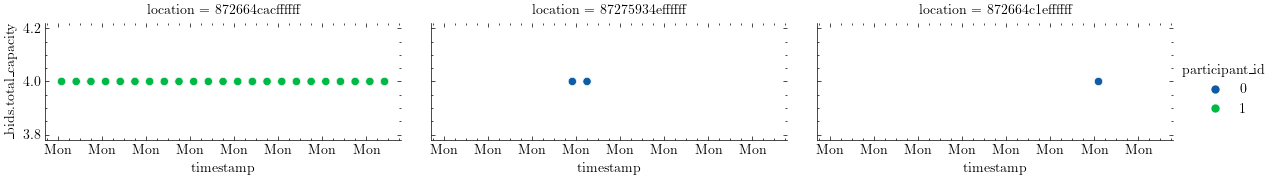

In [196]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_bids.total_capacity", hue="participant_id", col="location", col_wrap=3, kind="scatter", height=2, aspect = 2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

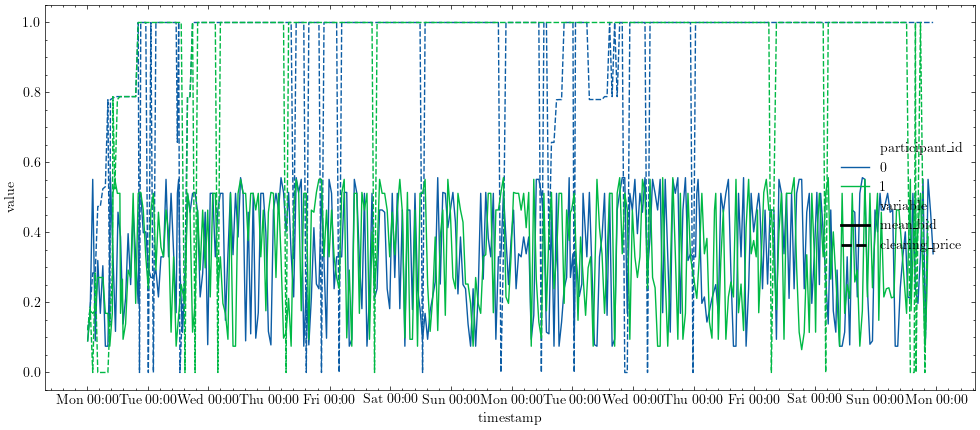

In [120]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(12,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [197]:
auction_tracking_hourly = auction_tracking.groupby('participant_id').resample('6h', on='timestamp').agg({'_bids.mean_bid': 'mean', '_result.clearing_price': 'mean'}).reset_index()

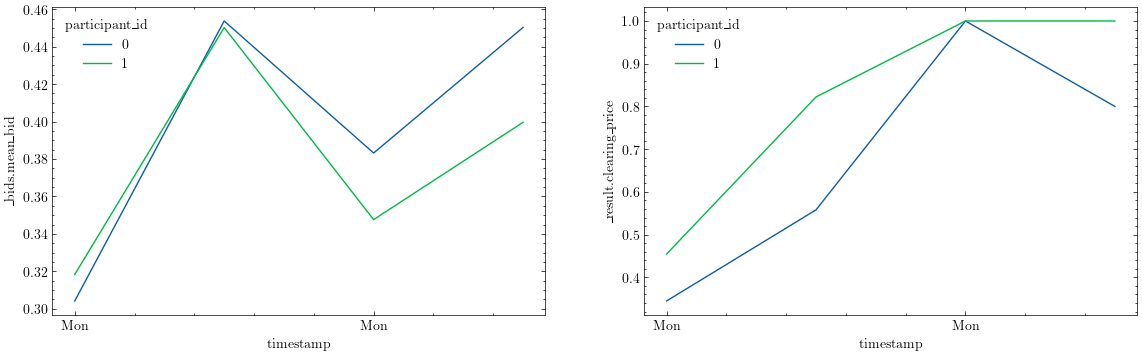

In [198]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,2, figsize=(14,4))

sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_bids.mean_bid", hue="participant_id", ax=ax[0])
sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_result.clearing_price", hue="participant_id", ax=ax[1])

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Vehicles

In [199]:
vehicle_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_vehicles.csv")

In [200]:
vehicle_tracking_coordinated['_state'].apply(lambda x: set(eval(x))).value_counts()

_state
{1, 2, 3, 5, 1003}             818
{1, 2, 1003}                   794
{1, 2, 3, 5, 1001, 1003}       673
{1, 2, 1003, 1001}             634
{1, 2, 3, 4, 1003}             541
{1, 2, 3, 4, 5, 1003}          478
{1, 2, 3, 4, 1001, 1003}       452
{1, 2, 3, 4, 5, 1001, 1003}    422
{1, 2, 3, 1003}                165
{1, 2, 3, 1001, 1003}          101
{1, 2, 1003, 4}                 98
{1, 2, 4, 1001, 1003}           86
{1, 2, 3, 4}                    68
{1, 2, 3, 4, 1001}              61
{1, 2, 3}                       47
{1, 2, 3, 1001}                 43
{1, 2, 4, 5, 1003}              43
{1, 2, 4, 5, 1001, 1003}        38
{1, 2, 3, 4, 5}                 31
{1, 2, 3, 5}                    28
{1, 2, 1003, 5}                 23
{1, 2}                          23
{1, 2, 3, 4, 5, 1001}           21
{1, 2, 5, 1001, 1003}           17
{1, 2, 3, 5, 1001}              16
{1, 2, 1001}                     9
{1, 2, 1001, 5}                  5
{1}                              4
{1, 2, 4, 5, 

In [201]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [202]:
# rename time axis
vehicle_tracking_coordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_coordinated['time'] = pd.to_datetime(vehicle_tracking_coordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


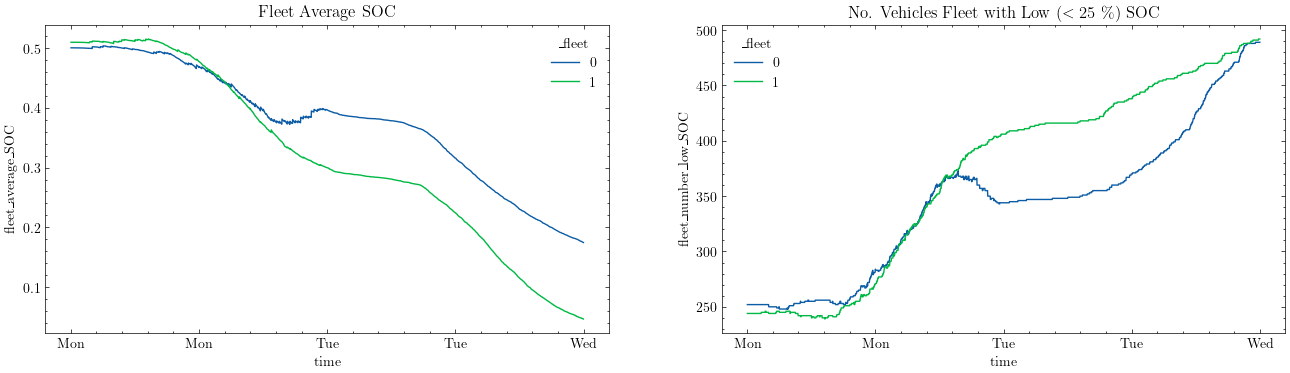

In [203]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

In [128]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [129]:
vehicle_tracking_coordinated['_state_PARKING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_coordinated['_state_CHARGING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_coordinated['_state_DRIVING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_coordinated['_state_RELOCATING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_coordinated['_state_PRE_SERVICE'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_coordinated['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_coordinated['_state_RESERVED'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

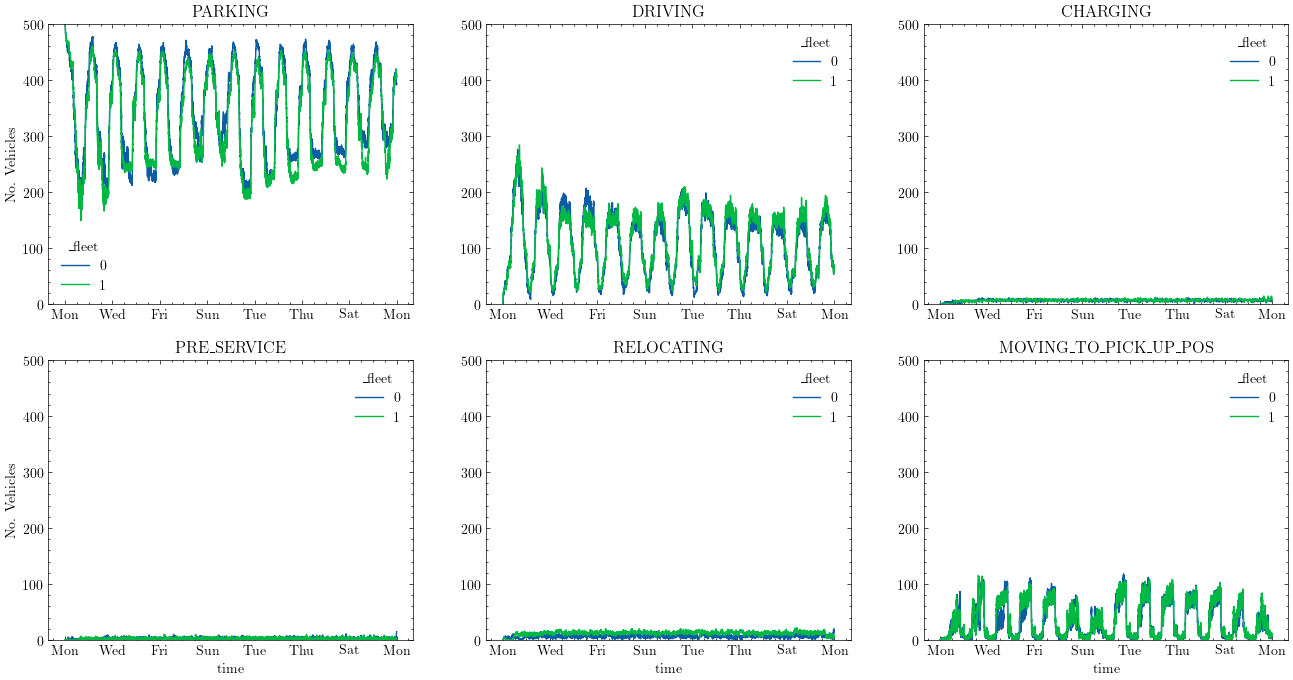

In [130]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [204]:
charging_station_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_charging_stations.csv")

In [205]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [206]:
charging_station_tracking_coordinated['utilization'] = charging_station_tracking_coordinated['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking_coordinated['system_wide_utilization'] = charging_station_tracking_coordinated.groupby('time')['utilization'].transform('mean')

In [207]:
# rename time axis
charging_station_tracking_coordinated['time'] = pd.to_datetime(charging_station_tracking_coordinated['time'].apply(SimulationTimeConverter.as_datetime))

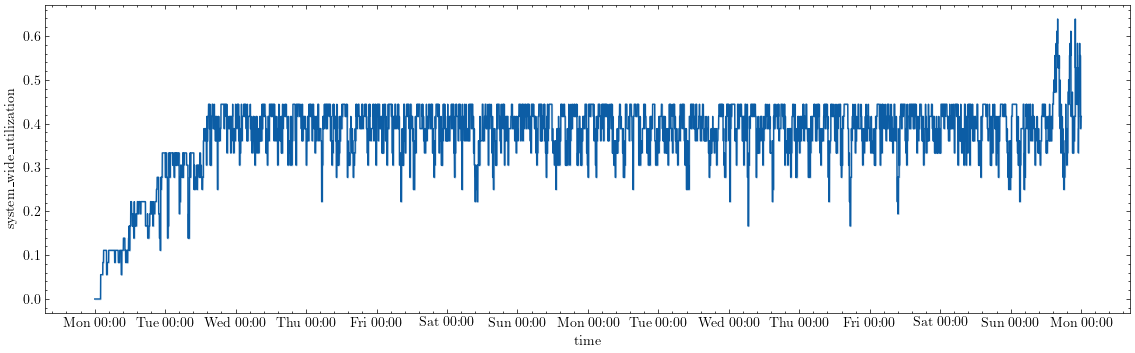

In [135]:
fig, ax = plt.subplots(1,1, figsize=(14,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


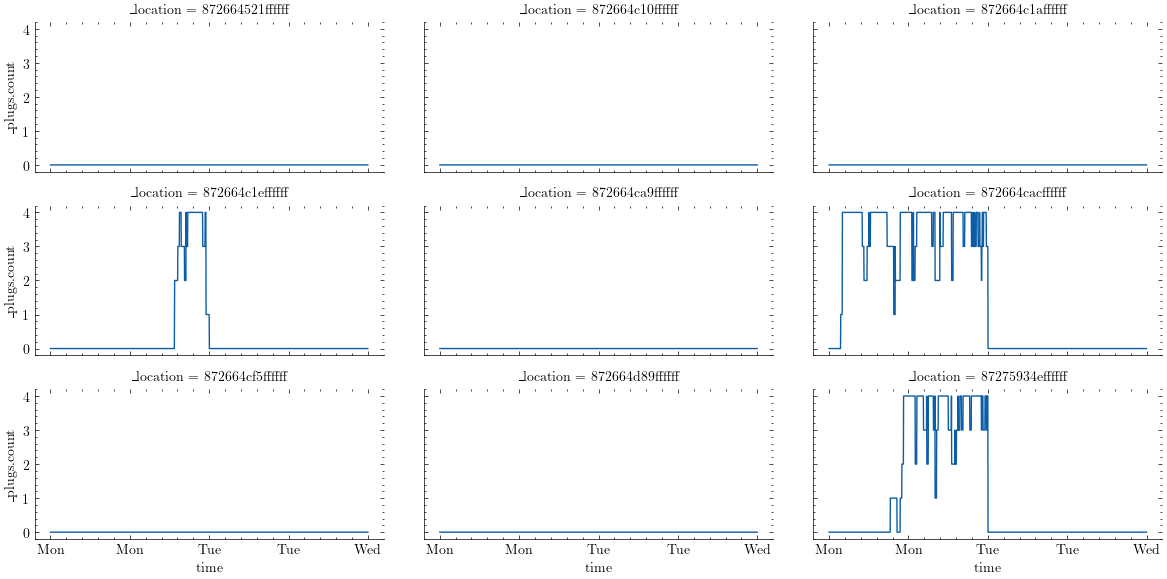

In [208]:
charging_station_tracking_coordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_coordinated, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=3, height=2, aspect=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


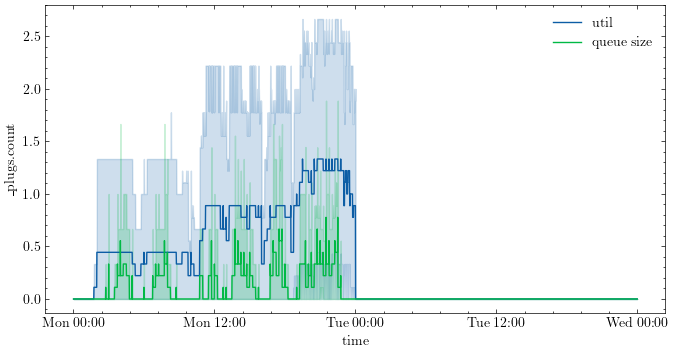

In [216]:
fig, ax = plt.subplots(1,1, figsize=(8,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.count', label='util', ax=ax)
sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.queuesize', label='queue size', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [160]:
charging_capa = charging_station_tracking_coordinated.groupby('_location').resample( '15min', on='time').agg({'_plugs.count': 'median'}).reset_index()

In [161]:
auction_capa = auction_tracking.groupby('location').resample('15min', on='timestamp').agg({'_bids.total_capacity': 'sum', '_result.capacity': 'sum'}).reset_index()

In [162]:
def parse_multiline_list(section: str, key: str, delimiter: str):
    multiline = (
        parser.get(section, key).replace("\n", "").replace(" ", "").split(delimiter)
    )
    return multiline

In [163]:
station_locations = parse_multiline_list("CHARGING_INFRASTRUCTURE", "LOCATIONS", ",")[:9]

In [164]:
auction_capa.sort_values(by=['timestamp', 'location'], inplace=True)
charging_capa.sort_values(by=['time', '_location'], inplace=True)

In [165]:
charging_capa.merge(auction_capa, left_on=['_location', 'time'], right_on=['location', 'timestamp'], how='left')

,_location,time,_plugs.count,location,timestamp,_bids.total_capacity,_result.capacity
0,872664521ffffff,2024-01-01 00:00:00,0.0,NaN,NaT,NaN,NaN
1,872664c10ffffff,2024-01-01 00:00:00,0.0,NaN,NaT,NaN,NaN
2,872664c1affffff,2024-01-01 00:00:00,0.0,NaN,NaT,NaN,NaN
3,872664c1effffff,2024-01-01 00:00:00,0.0,NaN,NaT,NaN,NaN
4,872664ca9ffffff,2024-01-01 00:00:00,0.0,NaN,NaT,NaN,NaN
...,...,...,...,...,...,...,...
12091,872664ca9ffffff,2024-01-14 23:45:00,0.0,NaN,NaT,NaN,NaN
12092,872664cacffffff,2024-01-14 23:45:00,2.0,NaN,NaT,NaN,NaN
12093,872664cf5ffffff,2024-01-14 23:45:00,3.0,NaN,NaT,NaN,NaN
12094,872664d89ffffff,2024-01-14 23:45:00,2.0,NaN,NaT,NaN,NaN


In [166]:
capa = charging_capa.merge(auction_capa, left_on=['_location', 'time'], right_on=['location', 'timestamp'], how='outer')
capa.drop(columns=['_location', 'timestamp'], inplace=True)

In [182]:
capa.sample(5)

,time,_plugs.count,location,_bids.total_capacity,_result.capacity,diff
4065,2024-01-01 08:15:00,0.0,NaN,NaN,NaN,NaN
4608,2024-01-07 00:00:00,1.0,872664c1effffff,0.0,0.0,-1.0
2351,2024-01-11 11:45:00,0.0,872664c10ffffff,0.0,0.0,0.0
2467,2024-01-12 16:45:00,2.0,872664c10ffffff,0.0,0.0,-2.0
1580,2024-01-03 11:00:00,0.0,NaN,NaN,NaN,NaN


In [188]:
capa.sort_values(['location', 'time']).groupby('location').rolling('15min', on='time', center=False).agg({'_plugs.count': 'max','_result.capacity': 'sum'}).reset_index()

,location,time,_plugs.count,_result.capacity
0,872664521ffffff,2024-01-07 17:45:00,0.0,4.0
1,872664521ffffff,2024-01-07 18:00:00,1.0,0.0
2,872664521ffffff,2024-01-07 18:15:00,1.0,0.0
3,872664521ffffff,2024-01-07 18:30:00,1.0,0.0
4,872664521ffffff,2024-01-07 18:45:00,1.0,0.0
...,...,...,...,...
8472,87275934effffff,2024-01-13 08:45:00,0.0,0.0
8473,87275934effffff,2024-01-13 09:00:00,0.0,0.0
8474,87275934effffff,2024-01-13 09:15:00,0.0,0.0
8475,87275934effffff,2024-01-13 09:30:00,0.0,0.0


In [169]:
capa.sort_values(['location', 'time']).groupby('location')['plugs.count'].rolling(4, min_periods=3, center=False).max().reset_index().plot(x='level_1', y='_plugs.count', legend=False)

KeyError: '_location'

In [170]:
capa['diff'] = capa['_result.capacity'] - capa['_plugs.count']

<Axes: ylabel='Frequency'>

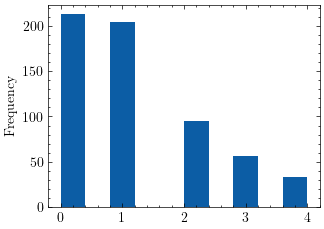

In [171]:
(auction_tracking['_bids.total_capacity'] - auction_tracking['_result.capacity']).plot(kind='hist')

<Axes: ylabel='Frequency'>

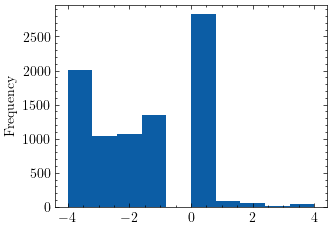

In [172]:
(capa['_result.capacity'] - capa['_plugs.count']).plot(kind='hist')

In [176]:
np.mean((capa['_bids.total_capacity'] == 0) & (capa['_result.capacity'] > 0))

0.0

In [177]:
np.mean(capa['_result.capacity'] < capa['_plugs.count'])

0.45188492063492064

In [174]:
any(charging_station_tracking_coordinated['_plugs.count'] > 4)

False

ValueError: Could not interpret value `_plugs.count` for `y`. An entry with this name does not appear in `data`.

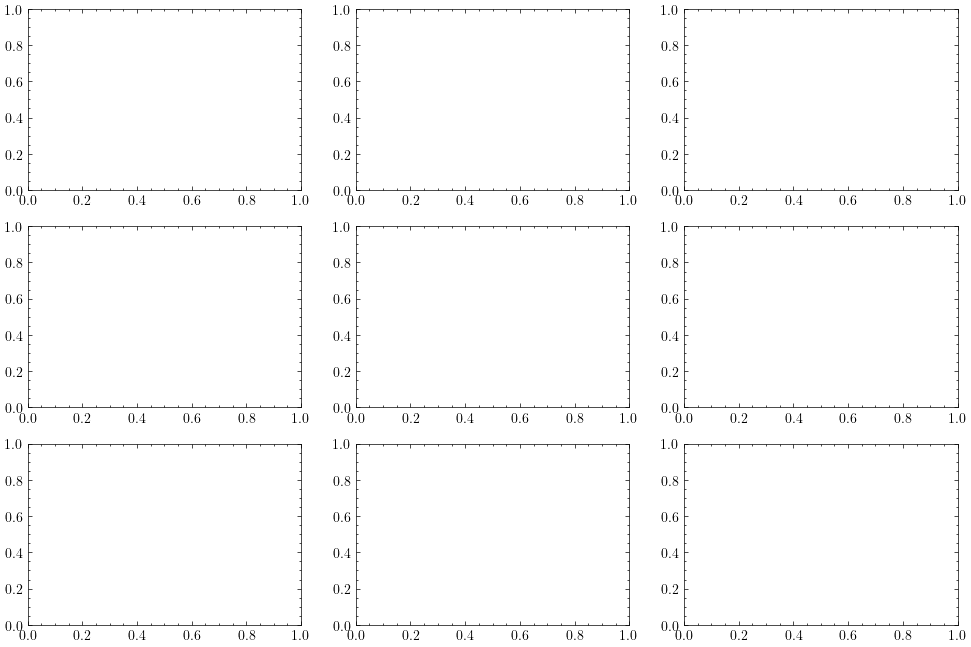

In [173]:
fig, ax = plt.subplots(3,3, figsize=(12, 8))

for i, s in enumerate(station_locations):
    a = ax[(i // 3)][i % 3]
    # print(f"[{(i // 3)}][{i % 3}]")
    
    sns.lineplot(data=auction_capa[auction_capa['location'] == s], x='timestamp', y='_plugs.count', label='used capacity', ax=a, legend=False, alpha = 0.5)
    sns.lineplot(data=auction_capa[auction_capa['location'] == s], x='timestamp', y='_result.capacity', label='sold capacity', ax=a, legend=False, alpha=0.5)
    a.set_title(s)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))
    
    if i == 5:
        a.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')

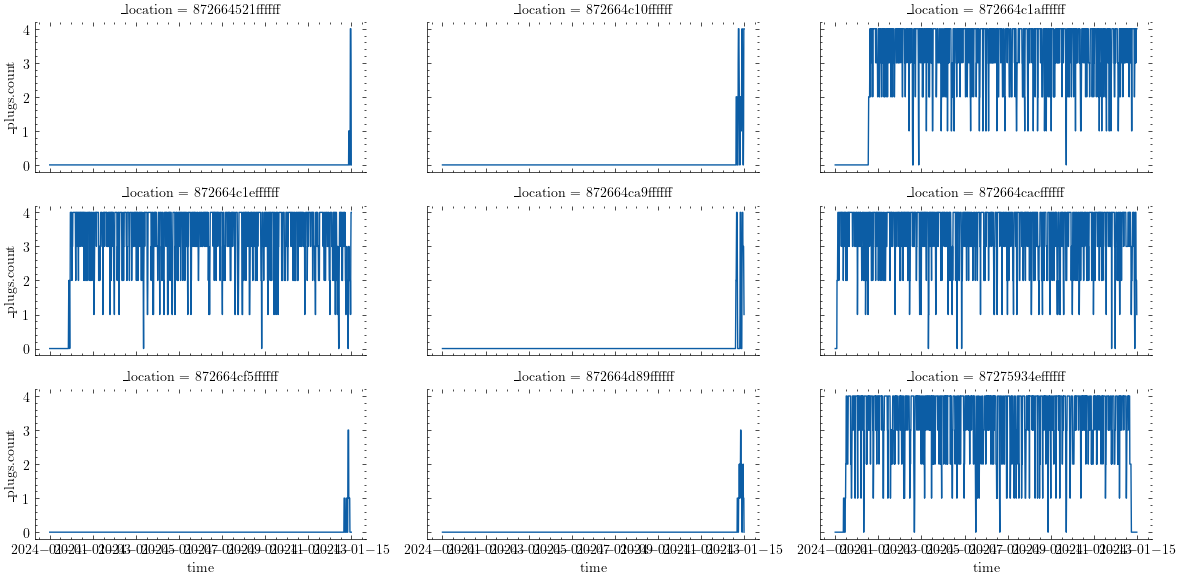

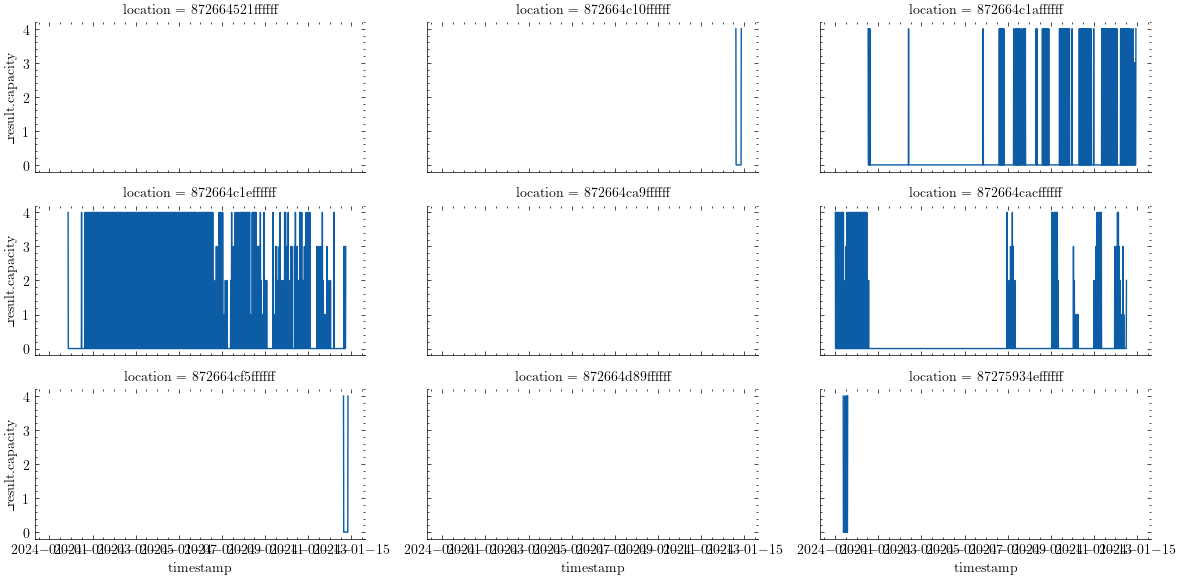

In [201]:
sns.relplot(data=charging_capa, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=3, height=2, aspect=2)
sns.relplot(data=auction_capa, x='timestamp', y='_result.capacity', col='location', kind='line', col_wrap=3, height=2, aspect=2)
axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Transactions

In [137]:
transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_transactions.csv")

In [138]:
RESAMPLE_RATE = '1h'

In [139]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'])
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'])
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [140]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
# transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
# transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

# transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
# transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

In [141]:
transactions_fleet_0_resampled

state                    
state               Fulfilled    MISSED   REFUSED
timestamp                                        
2024-01-01 00:00:00  0.235294       NaN  0.764706
2024-01-01 01:00:00  0.375000       NaN  0.625000
2024-01-01 02:00:00  0.521739       NaN  0.478261
2024-01-01 03:00:00  0.750000       NaN  0.250000
2024-01-01 04:00:00  0.575342       NaN  0.424658
...                       ...       ...       ...
2024-01-14 19:00:00  0.619048  0.107937  0.273016
2024-01-14 20:00:00  0.645161  0.149194  0.205645
2024-01-14 21:00:00  0.484694  0.244898  0.270408
2024-01-14 22:00:00  0.419355  0.376344  0.204301
2024-01-14 23:00:00  0.461111  0.327778  0.211111

[336 rows x 3 columns]

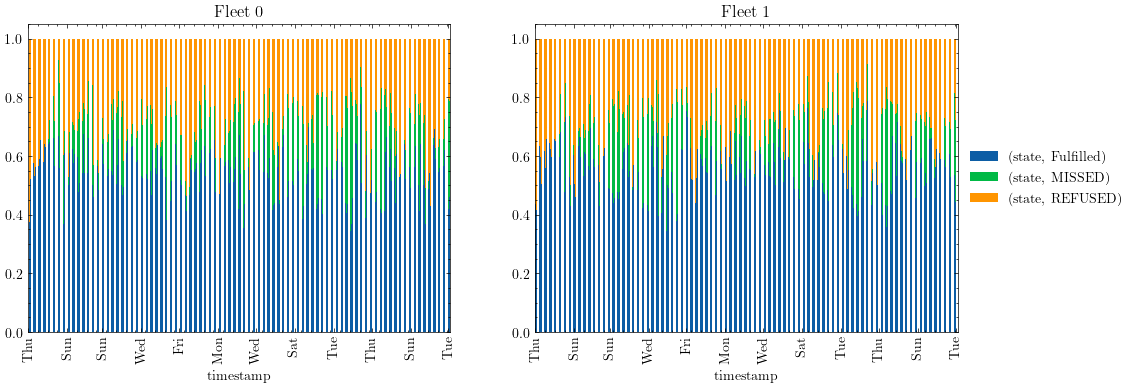

In [142]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

(0.0, 1.0)

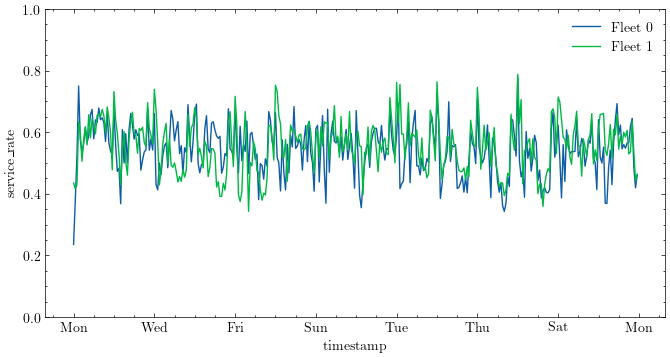

In [143]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [144]:
vehicle_tracking_coordinated['fleet_vdt'] = vehicle_tracking_coordinated['_vdt'].apply(lambda x: sum(eval(x)))

In [145]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [146]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

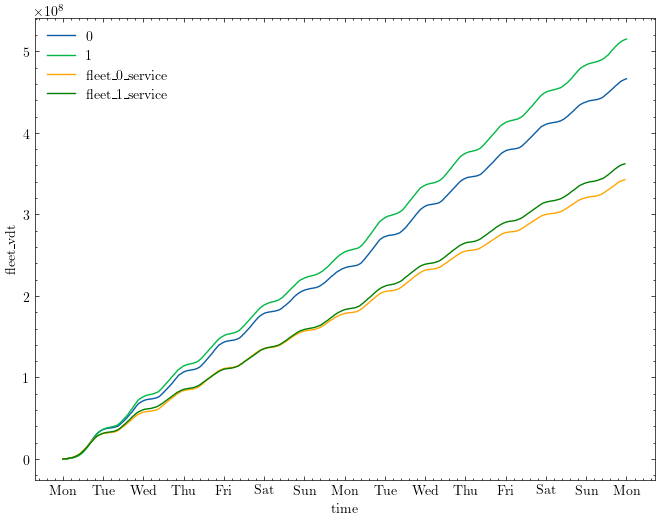

In [147]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [148]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking_coordinated.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [149]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [150]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [151]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [152]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
2024-01-01 00:00:00,4.016905e+04,3.742015e+04,32105.001389,3.210500e+04,32905.895408,32905.895408,0.200753,0.120637,40169.053030,37420.152557
2024-01-01 01:00:00,1.612277e+05,1.386363e+05,94470.992600,1.265760e+05,79665.836833,112571.732241,0.219626,0.212914,121058.612621,101216.141267
2024-01-01 02:00:00,4.718472e+05,3.538873e+05,248354.616091,3.749306e+05,154926.219192,267497.951433,0.200454,0.280253,310619.529905,215251.026890
2024-01-01 03:00:00,8.502006e+05,7.384889e+05,331929.611694,7.068602e+05,372187.868485,639685.819918,0.122700,0.032277,378353.449023,384601.628892
2024-01-01 04:00:00,1.292659e+06,1.106926e+06,405722.314823,1.112583e+06,342064.113695,981749.933613,0.083028,0.071580,442458.737050,368436.770281


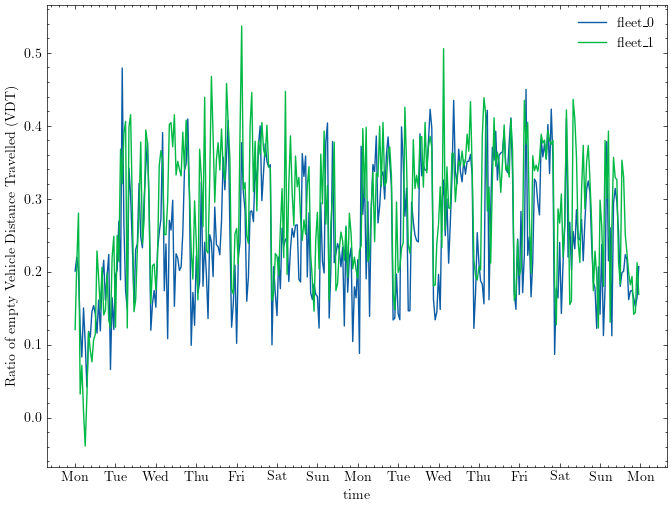

In [153]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Service Tasks

In [154]:
task_transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_task_transactions.csv")

In [155]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'])

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'])

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [156]:
task_transactions_fleet_0

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,16,180.0,5,TaskState.FINISHED,0,872664cacffffff,8.288710,60.0,22.0,2024-01-01 00:16:00,164.0
1,136,240.0,6,TaskState.FINISHED,0,872664cacffffff,11.536131,60.0,22.0,2024-01-01 02:16:00,104.0
2,16,240.0,1,TaskState.FINISHED,0,872664cacffffff,10.995812,60.0,22.0,2024-01-01 00:16:00,224.0
3,136,240.0,13,TaskState.FINISHED,0,872664cacffffff,9.508065,15.0,5.5,2024-01-01 02:16:00,104.0
4,76,240.0,15,TaskState.FINISHED,0,872664cacffffff,6.752178,0.0,0.0,2024-01-01 01:16:00,164.0
...,...,...,...,...,...,...,...,...,...,...,...
2485,20146,20160.0,485,TaskState.EXECUTING_RELOCATION,0,872664c1effffff,NaN,NaN,NaN,2024-01-14 23:46:00,14.0
2486,20146,20160.0,486,TaskState.EXECUTING_RELOCATION,0,872664c1affffff,NaN,NaN,NaN,2024-01-14 23:46:00,14.0
2487,20146,20160.0,487,TaskState.EXECUTING_RELOCATION,0,872664c1affffff,NaN,NaN,NaN,2024-01-14 23:46:00,14.0
2488,20146,20160.0,488,TaskState.EXECUTING_RELOCATION,0,872664c1affffff,NaN,NaN,NaN,2024-01-14 23:46:00,14.0


In [157]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                         
TaskState.FINISHED                2454
TaskState.EXECUTING_RELOCATION      30
TaskState.EXECUTING_CHARGING         6
Name: count, dtype: int64

state                         
TaskState.FINISHED                2626
TaskState.EXECUTING_CHARGING         9
TaskState.EXECUTING_RELOCATION       7
Name: count, dtype: int64

<Axes: xlabel='charging_duration', ylabel='kWh_charged'>

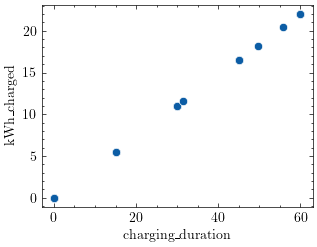

In [158]:
# check linearity
sns.scatterplot(data=task_transactions_fleet_0, x='charging_duration', y='kWh_charged')

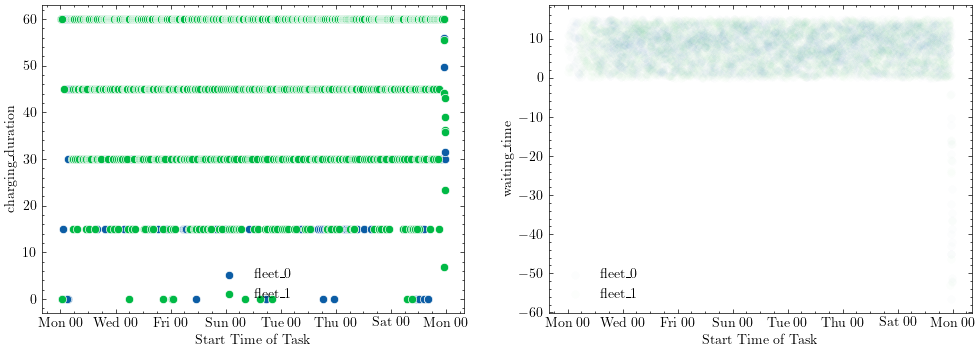

In [296]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1], alpha=.1)
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1], alpha=.1)

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H'))

In [160]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

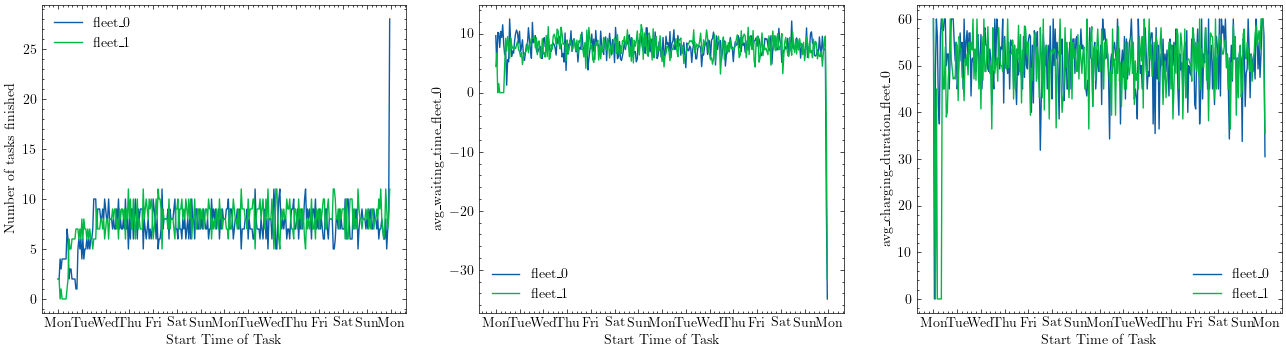

In [161]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS + 1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [162]:
date_range = range(0,parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME"), 15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [163]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_datetime)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'])

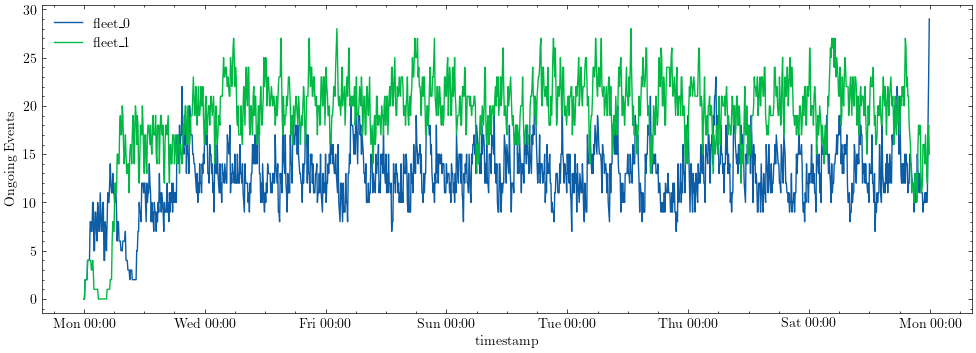

In [164]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))


In [165]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [166]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [167]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [168]:
tasks_incl_price.head()

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,16,180.0,5,TaskState.FINISHED,0,872664cacffffff,8.288710,60.0,22.0,2024-01-01 00:16:00,164.0,120.0,NaN,NaN,9.460
1,136,240.0,6,TaskState.FINISHED,0,872664cacffffff,11.536131,60.0,22.0,2024-01-01 02:16:00,104.0,180.0,NaN,NaN,9.460
2,16,240.0,1,TaskState.FINISHED,0,872664cacffffff,10.995812,60.0,22.0,2024-01-01 00:16:00,224.0,180.0,NaN,NaN,9.460
3,136,240.0,13,TaskState.FINISHED,0,872664cacffffff,9.508065,15.0,5.5,2024-01-01 02:16:00,104.0,225.0,NaN,NaN,2.365
4,76,240.0,15,TaskState.FINISHED,0,872664cacffffff,6.752178,0.0,0.0,2024-01-01 01:16:00,164.0,240.0,NaN,NaN,0.000


In [169]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

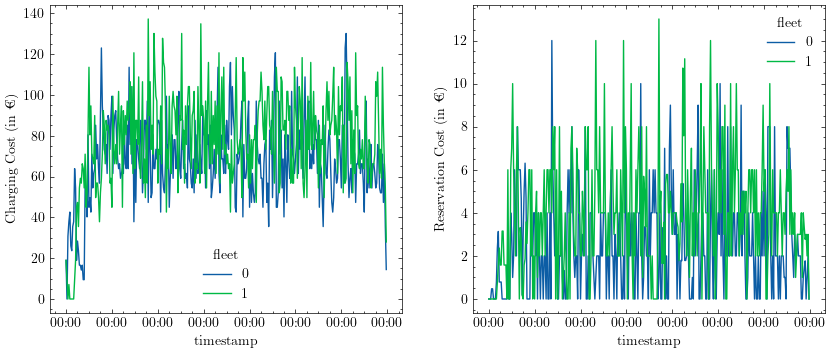

In [170]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Benchmarks: Single Infrastructure, No Coordination // Seperate Infrastructures

In [171]:
charging_station_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_charging_stations.csv")
vehicle_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_vehicles.csv")

charging_station_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_charging_stations.csv")
vehicle_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_vehicles.csv")

In [172]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_uncoordinated['fleet_average_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_uncoordinated['fleet_number_low_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

vehicle_tracking_seperate['fleet_average_SOC'] = vehicle_tracking_seperate['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_seperate['fleet_number_low_SOC'] = vehicle_tracking_seperate['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [173]:
# rename time axis
vehicle_tracking_uncoordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_uncoordinated['time'] = pd.to_datetime(vehicle_tracking_uncoordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

vehicle_tracking_seperate.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_seperate['time'] = pd.to_datetime(vehicle_tracking_seperate['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

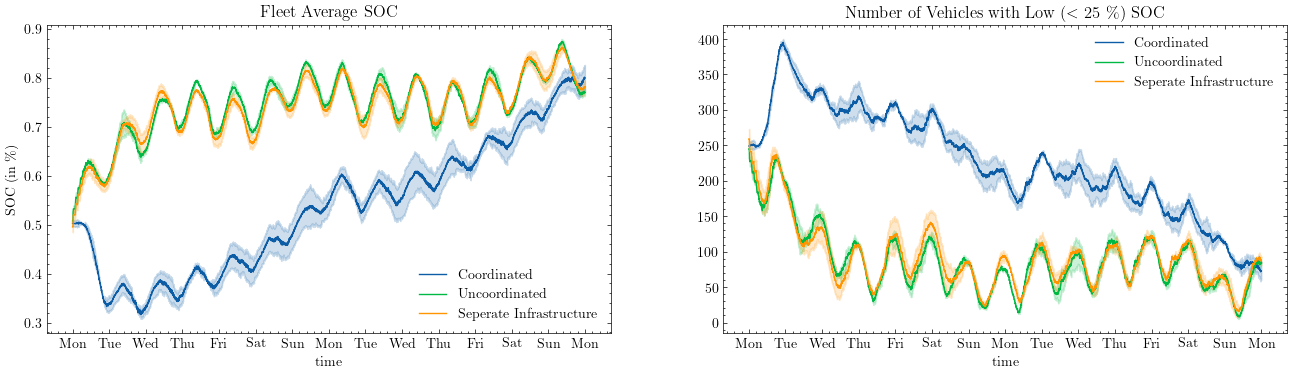

In [174]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_average_SOC', ax = ax[0], label='Seperate Infrastructure')

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Seperate Infrastructure')

ax[0].set_title('Fleet Average SOC')
ax[0].set_ylabel('SOC (in \%)')
ax[1].set_title(f'Number of Vehicles with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')
ax[1].set_ylabel('')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

In [175]:
charging_station_tracking_uncoordinated['utilization'] = charging_station_tracking_uncoordinated['_plugs.count'] / CHARGING_STATION_CAPACITY
charging_station_tracking_uncoordinated['system_wide_utilization'] = charging_station_tracking_uncoordinated.groupby('time')['utilization'].transform('mean')

charging_station_tracking_seperate['utilization'] = charging_station_tracking_seperate['_plugs.count'] / (CHARGING_STATION_CAPACITY / 2)
charging_station_tracking_seperate['system_wide_utilization'] = charging_station_tracking_seperate.groupby('time')['utilization'].transform('mean')

In [176]:
# rename time axis
charging_station_tracking_uncoordinated['time'] = pd.to_datetime(charging_station_tracking_uncoordinated['time'].apply(SimulationTimeConverter.as_datetime))
charging_station_tracking_seperate['time'] = pd.to_datetime(charging_station_tracking_seperate['time'].apply(SimulationTimeConverter.as_datetime))

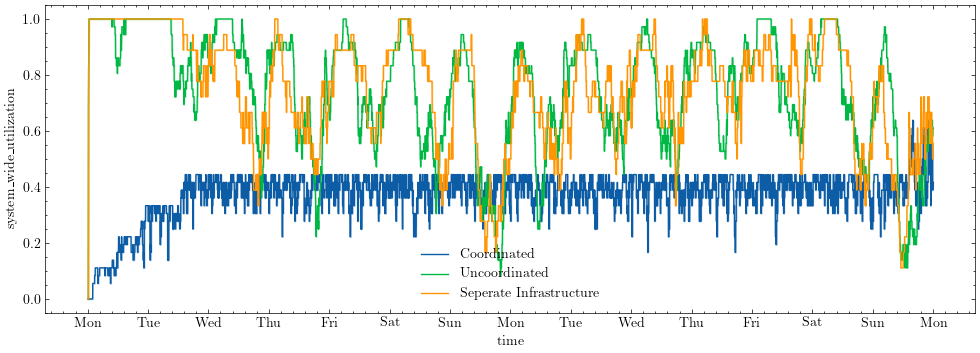

In [177]:
fig, ax = plt.subplots(1,1, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', label= 'Coordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_uncoordinated, x='time', y='system_wide_utilization', label= 'Uncoordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_seperate, x='time', y='system_wide_utilization', label= 'Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [178]:
transactions_fleet_0_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_1_transactions.csv")

transactions_fleet_0_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_0_transactions.csv")
transactions_fleet_1_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_1_transactions.csv")

In [179]:
transactions_fleet_0_uncoordinated['timestamp'] = transactions_fleet_0_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_0_uncoordinated['timestamp'])
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_uncoordinated['timestamp'] = transactions_fleet_1_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_1_uncoordinated['timestamp'])
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_0_seperate['timestamp'] = transactions_fleet_0_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_seperate['timestamp'] = pd.to_datetime(transactions_fleet_0_seperate['timestamp'])
transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_seperate['timestamp'] = transactions_fleet_1_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_seperate['timestamp'] = pd.to_datetime(transactions_fleet_1_seperate['timestamp'])
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()


# normalize
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated_resampled.div(transactions_fleet_0_uncoordinated_resampled.sum(axis=1), axis=0)
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated_resampled.div(transactions_fleet_1_uncoordinated_resampled.sum(axis=1), axis=0)

transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate_resampled.div(transactions_fleet_0_seperate_resampled.sum(axis=1), axis=0)
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate_resampled.div(transactions_fleet_1_seperate_resampled.sum(axis=1), axis=0)

# calc service rate, per fleet and overall
transactions_fleet_0_uncoordinated_resampled['service_rate'] = transactions_fleet_0_uncoordinated_resampled[('state', 'Fulfilled')]
transactions_fleet_1_uncoordinated_resampled['service_rate'] = transactions_fleet_1_uncoordinated_resampled[('state', 'Fulfilled')]

transactions_fleet_0_seperate_resampled['service_rate'] = transactions_fleet_0_seperate_resampled[('state', 'Fulfilled')]
transactions_fleet_1_seperate_resampled['service_rate'] = transactions_fleet_1_seperate_resampled[('state', 'Fulfilled')]

service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_seperate_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

service_rate_coordinated['service_rate'] = service_rate_coordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_uncoordinated['service_rate'] = service_rate_uncoordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_seperate['service_rate'] = service_rate_seperate[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)

/tmp/ipykernel_23177/2214906733.py:32: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/tmp/ipykernel_23177/2214906733.py:33: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/tmp/ipykernel_23177/2214906733.py:34: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].merg

(0.0, 1.0)

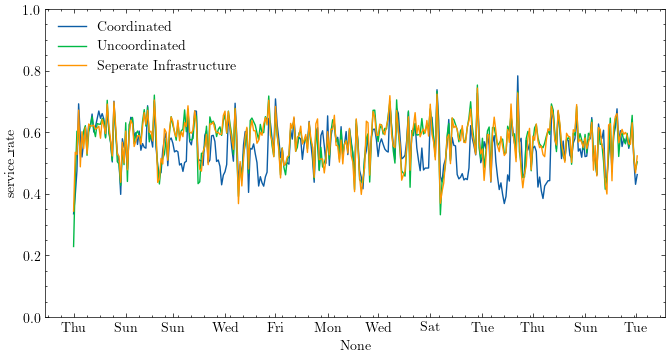

In [180]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

sns.lineplot(data=service_rate_coordinated, x = service_rate_coordinated.index, y = 'service_rate', label='Coordinated', ax=ax)
sns.lineplot(data=service_rate_uncoordinated, x = service_rate_uncoordinated.index, y = 'service_rate', label='Uncoordinated', ax=ax)
sns.lineplot(data=service_rate_seperate, x = service_rate_seperate.index, y = 'service_rate', label='Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

In [181]:
# TODO: empty VDT

### compare one day with Anthony's results

In [182]:
benchmark_no_coordination = pd.read_csv("data/output/benchmarks/time_related_kpi_500.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/output/benchmarks/time_related_kpi_500.csv'

In [ ]:
benchmark_no_coordination

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='all_vehicles_avg_SOC', figsize=(10, 4))

In [ ]:
benchmark_no_coordination['charging_utilization'] = benchmark_no_coordination['all_stations_utilization_rate'].apply(lambda x: np.mean(eval(x)))

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='charging_utilization', figsize=(10, 4))

In [ ]:
# compare to our scenario
benchmark_no_coordination['time'] = pd.to_datetime(benchmark_no_coordination['timestamp'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

fig, ax = plt.subplots(1,2, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax[0])
ax[0].set_ylabel('Charging Infrastructure Utilization')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='charging_utilization', ax=ax[1])
ax[1].set_ylabel('Charging Infrastructure Utilization')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 1.0)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS +  1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
ax[0].set_ylabel('Fleet Average SOC (in %)')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='all_vehicles_avg_SOC', ax=ax[1])
ax[1].set_ylabel('Fleet Average SOC (in %)')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 100)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [ ]:
benchmark_no_coordination['vehicles_avg_waiting_times'] = benchmark_no_coordination['all_vehicles_waiting_times'].apply(lambda x: np.mean([y[0] for y in eval(x) if len(y) > 0]))

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='vehicles_avg_waiting_times', ax=ax[1])


In [ ]:
metrics_no_coordination = pd.read_csv("data/output/benchmarks/end_of_sim_kpi_500.csv")

In [ ]:
metrics_no_coordination

In [ ]:
display(transactions_fleet_0.value_counts('state'))
display(transactions_fleet_1.value_counts('state'))

In [ ]:
pd.DataFrame([
    {
        'fleet': 0,
        'service_rate_coordination': sum(transactions_fleet_0['state'] == 'Fulfilled') / transactions_fleet_0.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_0_total_missed_trips_ride_hailing'])
    },
    {
        'fleet': 1,
        'service_rate_coordination': sum(transactions_fleet_1['state'] == 'Fulfilled') / transactions_fleet_1.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_1_total_missed_trips_ride_hailing'])
    }    
])

### other stuff

In [ ]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [ ]:
transactions_fleet_0['pick_up_time'].describe()